## 1. Load the data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data
from src.config import DATA_DIR

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR)
feature_names = np.genfromtxt(DATA_DIR / "x_train.csv", delimiter=",", dtype=str, max_rows=1)[1:]
assert x_train.shape[1] == len(feature_names)

## 2. Plotting helpers

These functions keep the plots consistent and avoid repeating the same calculations. BRFSS missing/unknown codes are excluded explicitly in each analysis.

In [3]:
AGE_LABELS = [
    "18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
    "55–59", "60–64", "65–69", "70–74", "75–79", "80+"
]


def get_feature(name):
    """Return a feature column by its BRFSS variable name."""
    idx = np.flatnonzero(feature_names == name)
    if len(idx) != 1:
        raise ValueError(f"Feature not found or ambiguous: {name}")
    return x_train[:, idx[0]]


def plot_categorical_prevalence(feature, categories, labels, title=None):
    """Plot and print unweighted MICHD prevalence for specified categories."""
    if len(categories) != len(labels):
        raise ValueError("categories and labels must have equal length")
    values = get_feature(feature)
    prevalence, counts = [], []
    for category in categories:
        mask = values == category
        n = np.count_nonzero(mask)
        counts.append(n)
        prevalence.append(100 * np.mean(y_train[mask] == 1) if n else np.nan)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(labels, prevalence)
    ax.set(xlabel=feature, ylabel="MICHD prevalence (%)",
           title=title or f"MICHD prevalence by {feature}")
    ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    plt.show()

    for label, n, p in zip(labels, counts, prevalence):
        print(f"{label:20s} | N = {n:6d} | MICHD = {p:.2f}%")
    return np.asarray(prevalence), np.asarray(counts)


def plot_age_stratified(feature, categories, labels, title=None):
    """Compare MICHD prevalence by age group for selected categories."""
    if len(categories) != len(labels):
        raise ValueError("categories and labels must have equal length")
    ages = get_feature("_AGEG5YR")
    values = get_feature(feature)
    fig, ax = plt.subplots(figsize=(11, 5))
    group_counts = {}

    for category, label in zip(categories, labels):
        counts, prevalences = [], []
        for group in range(1, 14):  # 14 = missing age
            mask = (ages == group) & (values == category)
            n = np.count_nonzero(mask)
            counts.append(n)
            prevalences.append(100 * np.mean(y_train[mask] == 1) if n else np.nan)
        group_counts[label] = np.asarray(counts)
        ax.plot(AGE_LABELS, prevalences, marker="o", label=label)

    ax.set(xlabel="Age group", ylabel="MICHD prevalence (%)",
           title=title or f"MICHD prevalence by age and {feature}")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()
    return group_counts

## 3. Dataset overview and missingness

### 3.1 Dimensions and target balance

Training: (328135, 321) | Test: (109379, 321)
Labels: (328135,) | Features: 321 | dtype: float64
NaN cells: 47,175,779
Class -1: 299,160 (91.17%)
Class +1: 28,975 (8.83%)


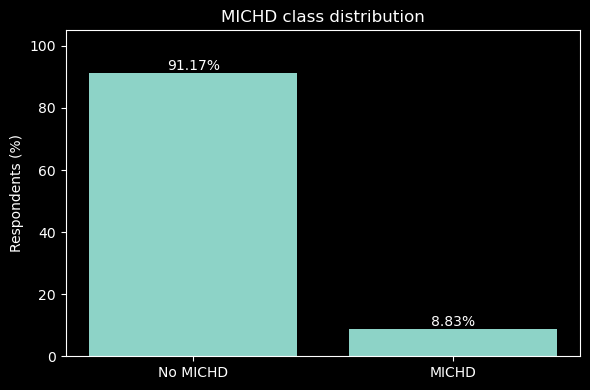

In [4]:
print(f"Training: {x_train.shape} | Test: {x_test.shape}")
print(f"Labels: {y_train.shape} | Features: {len(feature_names)} | dtype: {x_train.dtype}")
print(f"NaN cells: {np.isnan(x_train).sum():,}")

classes, counts = np.unique(y_train, return_counts=True)
percentages = counts / len(y_train) * 100
for cls, count, pct in zip(classes, counts, percentages):
    print(f"Class {cls:+d}: {count:,} ({pct:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["No MICHD" if cls == -1 else "MICHD" for cls in classes]
bars = ax.bar(labels, percentages)
for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{pct:.2f}%", ha="center")
ax.set(ylabel="Respondents (%)", title="MICHD class distribution", ylim=(0, 105))
fig.tight_layout()
plt.show()

**Finding.** MICHD-positive respondents account for approximately **8.83%** of training observations. Predicting the negative class for everyone would therefore yield about **91.17% accuracy**, but zero recall for MICHD.

### 3.2 Missing values by feature and respondent

`NaN` is only one type of missingness in BRFSS: depending on the question, codes such as `7`, `9`, `77`, `99` or `99900` can also mean unknown, refused, or not applicable. They need **feature-specific** treatment later in preprocessing.

Columns above missingness thresholds:
 > 0%: 239
 >10%: 182
 >30%: 177
 >50%: 147
 >70%: 121
 >90%:  99

Top 20 columns:
LADULT         :  99.99%
COLGHOUS       :  99.99%
PCDMDECN       :  99.95%
ASDRVIST       :  99.93%
ASERVIST       :  99.93%
ASNOSLEP       :  99.90%
ASINHALR       :  99.85%
ASTHMED3       :  99.85%
ASYMPTOM       :  99.85%
ASACTLIM       :  99.85%
ASRCHKUP       :  99.85%
ASATTACK       :  99.85%
STREHAB1       :  99.84%
PCPSADE1       :  99.82%
HAREHAB1       :  99.76%
ASTHMAGE       :  99.76%
VINOCRE2       :  99.76%
CCLGHOUS       :  99.76%
HPVADSHT       :  99.67%
VIEYEXM2       :  99.43%


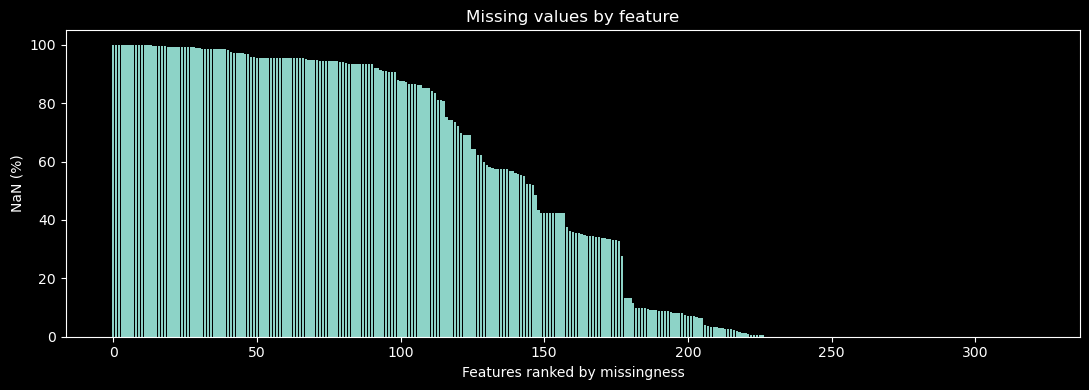

In [5]:
missing_pct = np.mean(np.isnan(x_train), axis=0) * 100
sorted_idx = np.argsort(missing_pct)[::-1]

print("Columns above missingness thresholds:")
for threshold in (0, 10, 30, 50, 70, 90):
    print(f" >{threshold:2d}%: {np.sum(missing_pct > threshold):3d}")
print("\nTop 20 columns:")
for i in sorted_idx[:20]:
    print(f"{feature_names[i]:15s}: {missing_pct[i]:6.2f}%")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(len(feature_names)), missing_pct[sorted_idx])
ax.set(xlabel="Features ranked by missingness", ylabel="NaN (%)",
       title="Missing values by feature")
fig.tight_layout()
plt.show()

Mean: 44.79% | Median: 43.30%
Std: 5.79%
Percentiles (0, 25, 50, 75, 100): [24.92211838 41.12149533 43.30218069 47.35202492 67.91277259]


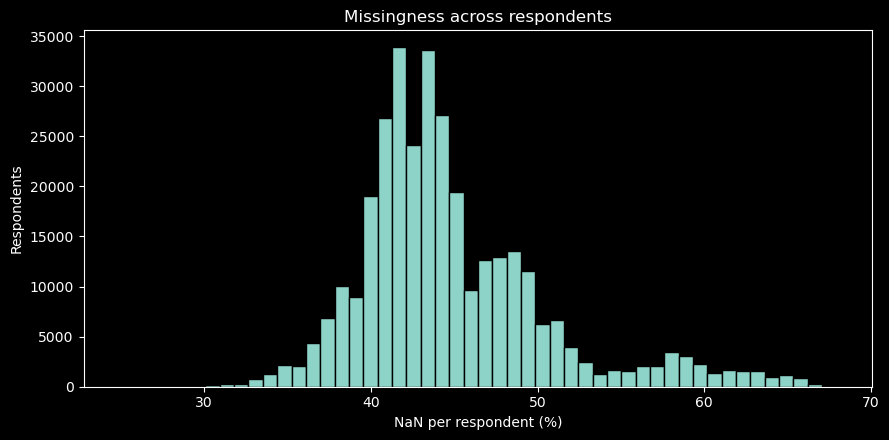

In [6]:
row_missing_pct = np.mean(np.isnan(x_train), axis=1) * 100
print(f"Mean: {row_missing_pct.mean():.2f}% | Median: {np.median(row_missing_pct):.2f}%")
print(f"Std: {row_missing_pct.std():.2f}%")
print("Percentiles (0, 25, 50, 75, 100):", np.percentile(row_missing_pct, [0, 25, 50, 75, 100]))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(row_missing_pct, bins=50, edgecolor="black")
ax.set(xlabel="NaN per respondent (%)", ylabel="Respondents",
       title="Missingness across respondents")
fig.tight_layout()
plt.show()

No MICHD: mean 44.85%, median 43.61%
MICHD:    mean 44.12%, median 42.99%


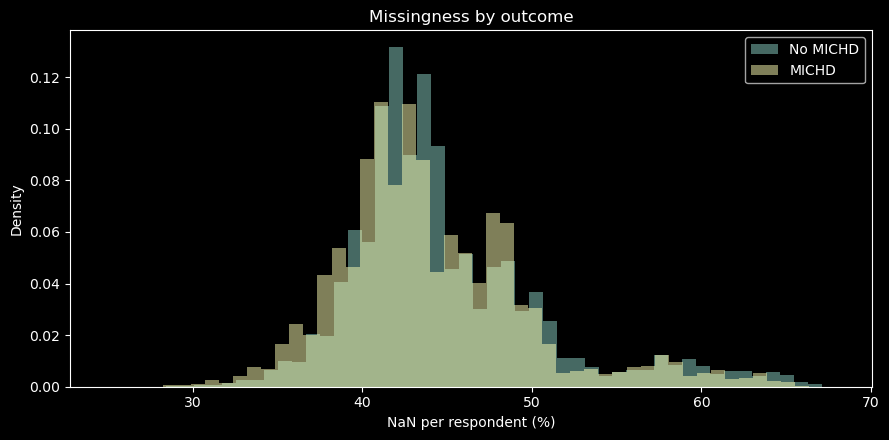

In [7]:
negative = row_missing_pct[y_train == -1]
positive = row_missing_pct[y_train == 1]
print(f"No MICHD: mean {negative.mean():.2f}%, median {np.median(negative):.2f}%")
print(f"MICHD:    mean {positive.mean():.2f}%, median {np.median(positive):.2f}%")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(negative, bins=50, density=True, alpha=0.5, label="No MICHD")
ax.hist(positive, bins=50, density=True, alpha=0.5, label="MICHD")
ax.set(xlabel="NaN per respondent (%)", ylabel="Density",
       title="Missingness by outcome")
ax.legend()
fig.tight_layout()
plt.show()

**Finding.** Approximately **44.79%** of training entries are `NaN`; **99/321** features have over 90% missingness. Every respondent has some missing entries, likely reflecting questionnaire structure and optional modules. Mean row missingness differs only slightly between MICHD and non-MICHD respondents (**44.12% vs 44.85%**). These descriptive findings do not establish whether missingness is random.

## 4. MICHD and demographic factors

### 4.1 Age

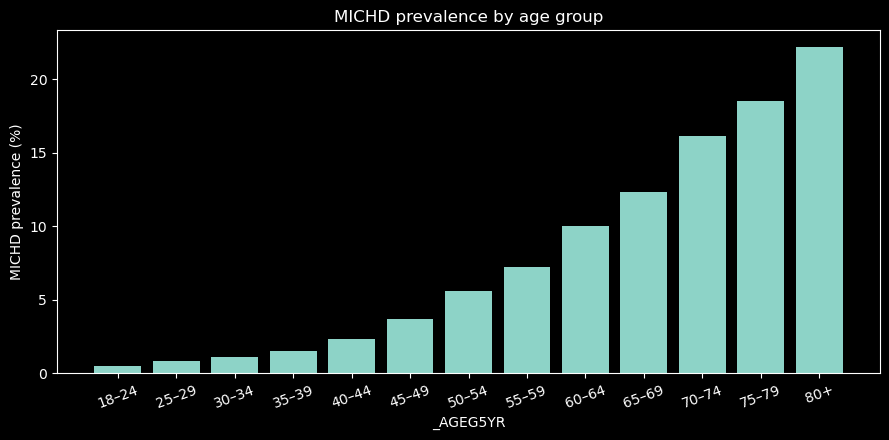

18–24                | N =  18145 | MICHD = 0.51%
25–29                | N =  14686 | MICHD = 0.85%
30–34                | N =  17122 | MICHD = 1.12%
35–39                | N =  18308 | MICHD = 1.47%
40–44                | N =  19296 | MICHD = 2.32%
45–49                | N =  22539 | MICHD = 3.66%
50–54                | N =  29693 | MICHD = 5.59%
55–59                | N =  34379 | MICHD = 7.21%
60–64                | N =  37210 | MICHD = 9.99%
65–69                | N =  36665 | MICHD = 12.34%
70–74                | N =  28190 | MICHD = 16.11%
75–79                | N =  20893 | MICHD = 18.50%
80+                  | N =  27066 | MICHD = 22.22%


In [8]:
age_prevalence, age_counts = plot_categorical_prevalence(
    "_AGEG5YR", list(range(1, 14)), AGE_LABELS,
    title="MICHD prevalence by age group"
)

**Finding.** MICHD prevalence increases strongly with age, from below 1% among the youngest respondents to over 20% among those aged 80+. The pattern motivates testing nonlinear age representations later.

### 4.2 Sex

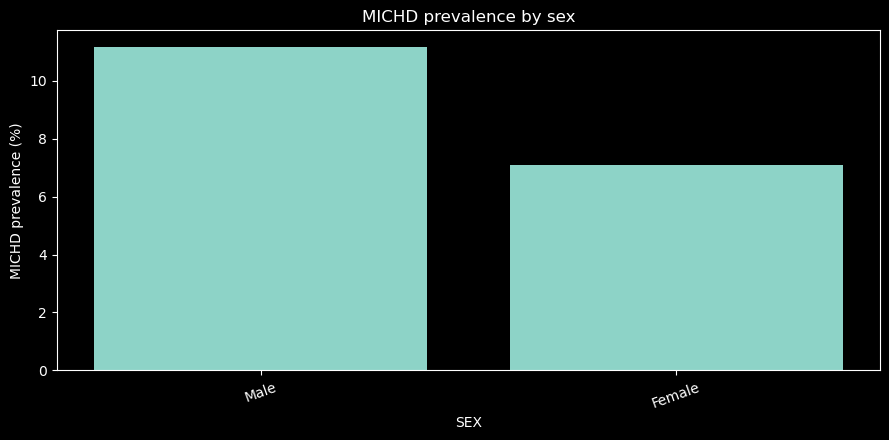

Male                 | N = 138783 | MICHD = 11.18%
Female               | N = 189352 | MICHD = 7.11%


In [9]:
sex_prevalence, sex_counts = plot_categorical_prevalence(
    "SEX", [1, 2], ["Male", "Female"],
    title="MICHD prevalence by sex"
)

**Finding.** MICHD prevalence is **11.18%** for male respondents versus **7.11%** for female respondents (crude prevalence ratio ≈ **1.57**).

### 4.3 Sex within age groups

Stratifying by age helps distinguish sex differences from differences in the age composition of the groups.

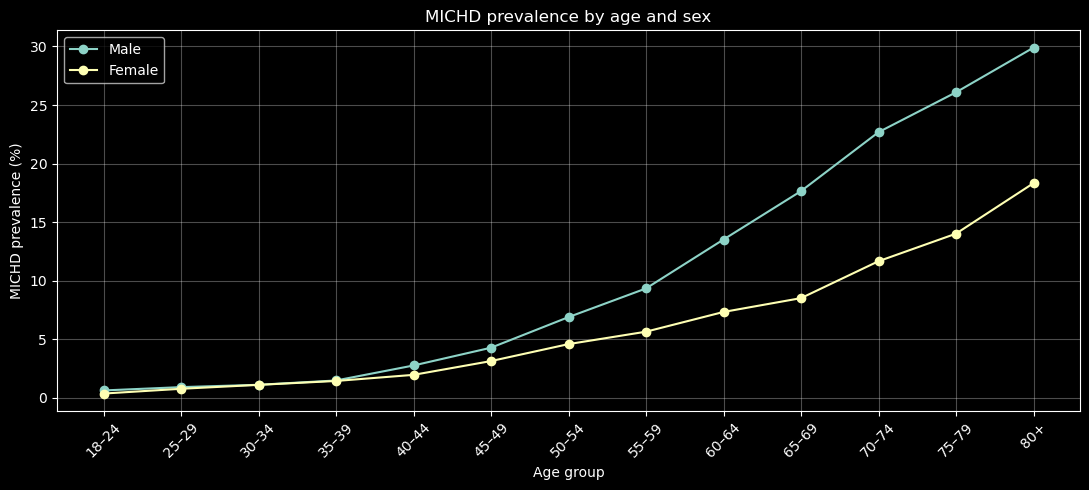

In [10]:
sex_age_counts = plot_age_stratified(
    "SEX", [1, 2], ["Male", "Female"],
    title="MICHD prevalence by age and sex"
)

**Finding.** Prevalence rises with age for both sexes. The absolute gap becomes noticeably larger in older age groups. This motivates testing an age–sex interaction during model development, without assuming one on the logistic scale.

## 5. Cardiometabolic factors

### 5.1 High blood pressure (`BPHIGH4`)

Codes: `1` diagnosed high blood pressure; `2` during pregnancy only; `3` no high blood pressure; `4` borderline. Unknown/refused responses are excluded.

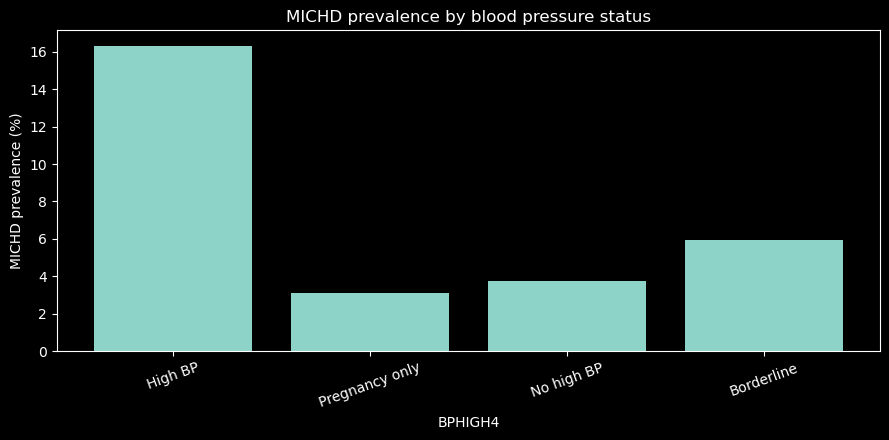

High BP              | N = 131801 | MICHD = 16.34%
Pregnancy only       | N =   2431 | MICHD = 3.13%
No high BP           | N = 189743 | MICHD = 3.73%
Borderline           | N =   3242 | MICHD = 5.95%


In [11]:
bp_prevalence, bp_counts = plot_categorical_prevalence(
    "BPHIGH4", [1, 2, 3, 4],
    ["High BP", "Pregnancy only", "No high BP", "Borderline"],
    title="MICHD prevalence by blood pressure status"
)

**Finding.** MICHD prevalence is **16.34%** among respondents with high BP versus **3.73%** among those without (crude prevalence ratio ≈ **4.38**). Age may partly explain the association.

#### High blood pressure within age groups

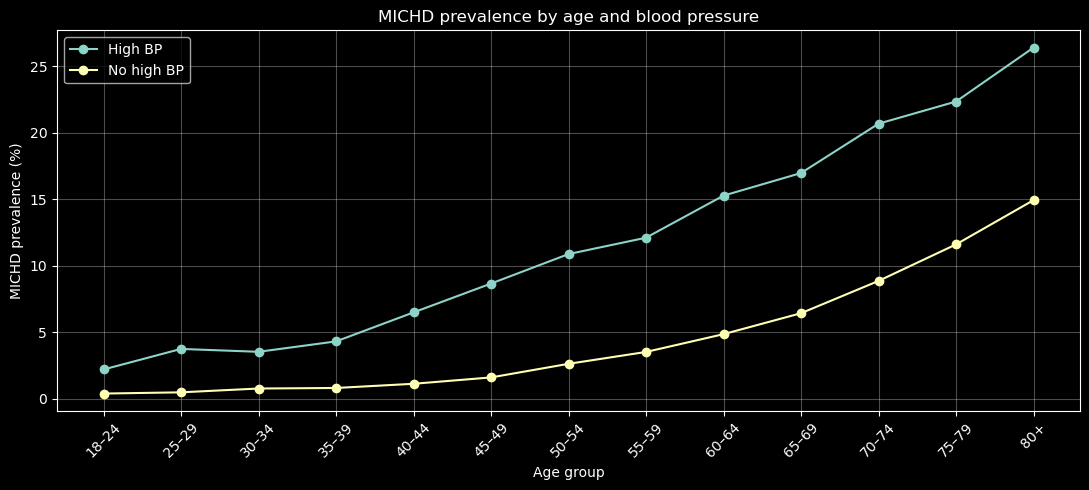

18–24    | High BP:   1274 | No high BP:  16581
25–29    | High BP:   1522 | No high BP:  12752
30–34    | High BP:   2211 | No high BP:  14367
35–39    | High BP:   3132 | No high BP:  14639
40–44    | High BP:   4297 | No high BP:  14534
45–49    | High BP:   6395 | No high BP:  15693
50–54    | High BP:  10531 | No high BP:  18602
55–59    | High BP:  14637 | No high BP:  19135
60–64    | High BP:  18285 | No high BP:  18288
65–69    | High BP:  20531 | No high BP:  15531
70–74    | High BP:  17244 | No high BP:  10485
75–79    | High BP:  13426 | No high BP:   7116
80+      | High BP:  16948 | No high BP:   9600


In [12]:
bp_age_counts = plot_age_stratified(
    "BPHIGH4", [1, 3], ["High BP", "No high BP"],
    title="MICHD prevalence by age and blood pressure"
)
for age_label, n_high, n_no in zip(AGE_LABELS, bp_age_counts["High BP"], bp_age_counts["No high BP"]):
    print(f"{age_label:8s} | High BP: {n_high:6d} | No high BP: {n_no:6d}")

**Finding.** At every age group, MICHD prevalence is higher among respondents reporting high BP. Both curves increase with age. The youngest high-BP group has fewer observations, so its estimate is less precise.

### 5.2 Diabetes (`DIABETE3`)

Codes: `1` diabetes; `2` during pregnancy only; `3` no diabetes; `4` prediabetes/borderline. Unknown/refused responses are excluded.

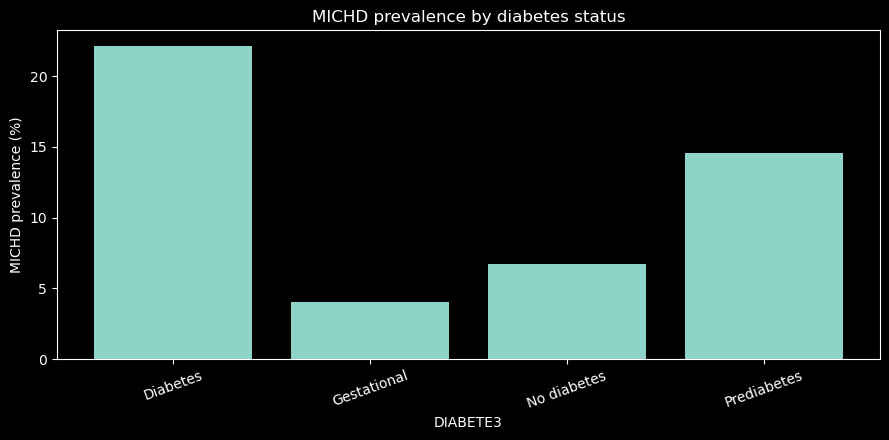

Diabetes             | N =  42223 | MICHD = 22.13%
Gestational          | N =   2675 | MICHD = 4.04%
No diabetes          | N = 277049 | MICHD = 6.73%
Prediabetes          | N =   5709 | MICHD = 14.54%


In [13]:
diabetes_prevalence, diabetes_counts = plot_categorical_prevalence(
    "DIABETE3", [1, 2, 3, 4],
    ["Diabetes", "Gestational", "No diabetes", "Prediabetes"],
    title="MICHD prevalence by diabetes status"
)

**Finding.** MICHD prevalence is **22.13%** with diabetes, **14.54%** with prediabetes and **6.73%** without diabetes. This is an unadjusted association; predictive contribution remains to be validated.

### 5.3 Body mass index (BMI)

We start with the predefined BMI categories, then inspect the continuous `_BMI5` measure and its relationship with age. In this dataset `_BMI5` is already expressed in ordinary BMI units.

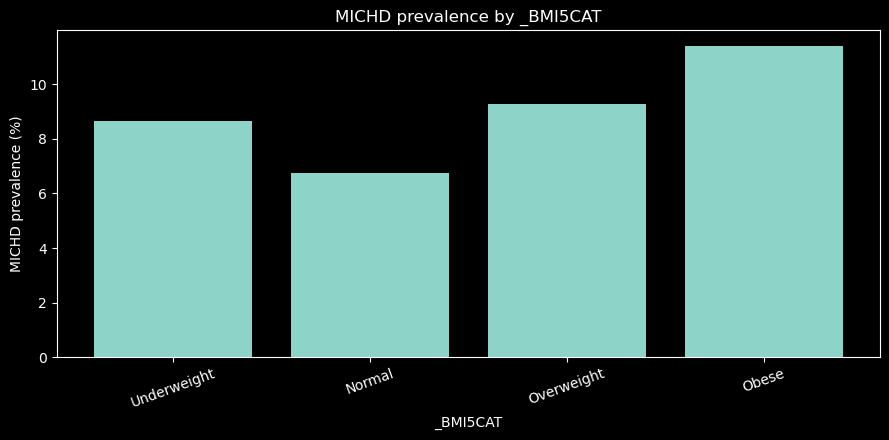

Underweight          | N =   5022 | MICHD = 8.66%
Normal               | N =  97813 | MICHD = 6.74%
Overweight           | N = 109376 | MICHD = 9.29%
Obese                | N =  88851 | MICHD = 11.41%


(array([ 8.66188769,  6.73836811,  9.28540082, 11.41123904]),
 array([  5022,  97813, 109376,  88851]))

In [14]:
plot_categorical_prevalence(
    "_BMI5CAT",
    [1, 2, 3, 4],
    ["Underweight", "Normal", "Overweight", "Obese"]
)

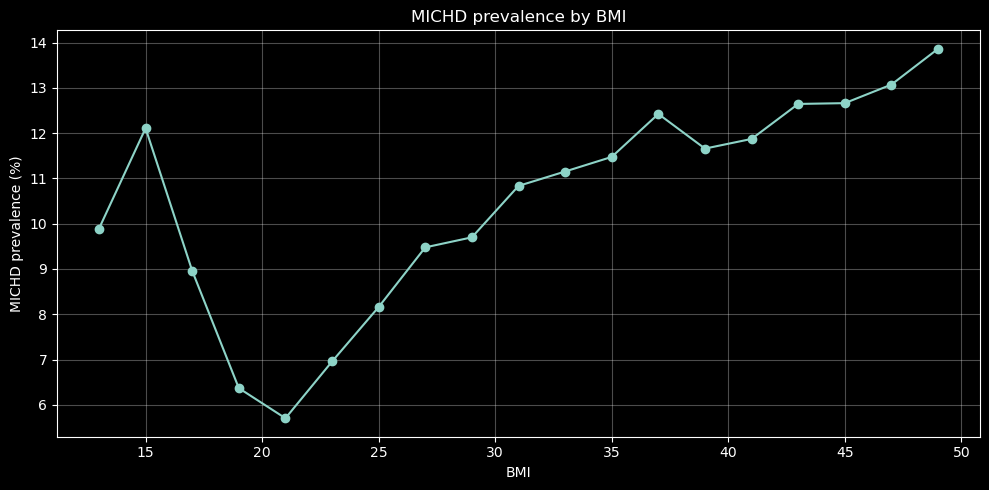

BMI 13.0 | N =     91 | MICHD = 9.89%
BMI 15.0 | N =    479 | MICHD = 12.11%
BMI 17.0 | N =   2690 | MICHD = 8.96%
BMI 19.0 | N =  11477 | MICHD = 6.37%
BMI 21.0 | N =  26768 | MICHD = 5.70%
BMI 23.0 | N =  38620 | MICHD = 6.96%
BMI 25.0 | N =  51159 | MICHD = 8.16%
BMI 27.0 | N =  42944 | MICHD = 9.48%
BMI 29.0 | N =  37983 | MICHD = 9.70%
BMI 31.0 | N =  27126 | MICHD = 10.83%
BMI 33.0 | N =  19933 | MICHD = 11.15%
BMI 35.0 | N =  12959 | MICHD = 11.47%
BMI 37.0 | N =   8798 | MICHD = 12.42%
BMI 39.0 | N =   6133 | MICHD = 11.66%
BMI 41.0 | N =   4296 | MICHD = 11.87%
BMI 43.0 | N =   2776 | MICHD = 12.64%
BMI 45.0 | N =   1856 | MICHD = 12.66%
BMI 47.0 | N =   1247 | MICHD = 13.07%
BMI 49.0 | N =    909 | MICHD = 13.86%


In [15]:
bmi = get_feature("_BMI5")
bins = np.arange(12, 52, 2)
centers = (bins[:-1] + bins[1:]) / 2

counts = []
prevalences = []
for low, high in zip(bins[:-1], bins[1:]):
    mask = (bmi >= low) & (bmi < high)
    n = mask.sum()
    counts.append(n)
    prevalences.append(100 * np.mean(y_train[mask] == 1) if n else np.nan)

plt.figure(figsize=(10, 5))
plt.plot(centers, prevalences, marker="o")
plt.xlabel("BMI")
plt.ylabel("MICHD prevalence (%)")
plt.title("MICHD prevalence by BMI")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for center, n, p in zip(centers, counts, prevalences):
    print(f"BMI {center:4.1f} | N = {n:6d} | MICHD = {p:.2f}%")

### Findings — BMI

MICHD prevalence exhibits an approximately J-shaped association with BMI, reaching its minimum around BMI 20–22 and generally increasing at higher BMI values.

Elevated prevalence is also observed among underweight respondents, although estimates at very low BMI values are based on smaller samples and are therefore less stable.

These findings suggest that nonlinear representations of BMI may be worth evaluating during model development.

Age-stratified analysis is needed to investigate potential confounding. The observed relationships are descriptive and do not establish causality.

#### BMI within age groups

We suppress bins with fewer than 100 observations to avoid plotting unstable estimates.

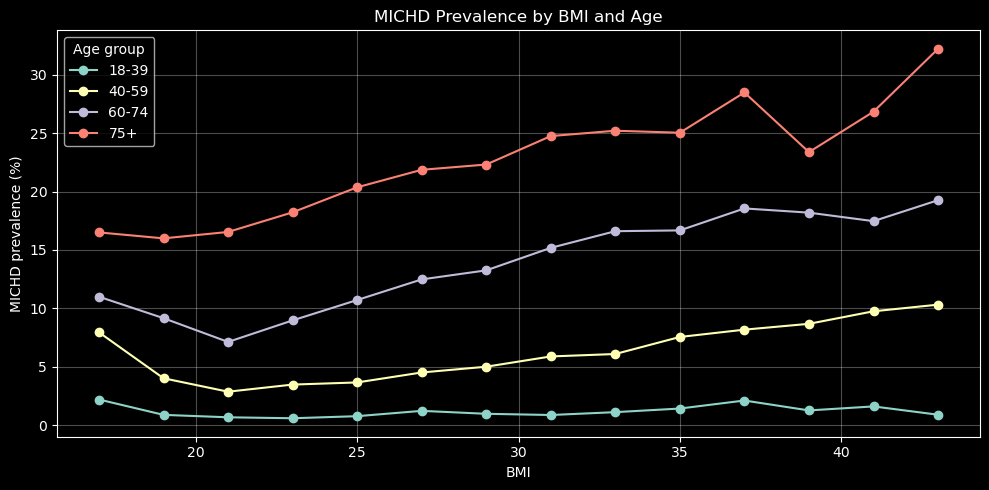

In [16]:
bmi = get_feature("_BMI5")
age = get_feature("_AGEG5YR")

bins = np.arange(16, 46, 2)
centers = (bins[:-1] + bins[1:]) / 2

age_groups = {
    "18-39": (1, 4),
    "40-59": (5, 8),
    "60-74": (9, 11),
    "75+": (12, 13)
}

plt.figure(figsize=(10, 5))

for label, (low_age, high_age) in age_groups.items():
    prevalences = []

    age_mask = (age >= low_age) & (age <= high_age)

    for lower, upper in zip(bins[:-1], bins[1:]):
        mask = age_mask & (bmi >= lower) & (bmi < upper)
        n = np.sum(mask)

        prevalences.append(
            100 * np.mean(y_train[mask] == 1)
            if n >= 100 else np.nan
        )

    plt.plot(centers, prevalences, marker="o", label=label)

plt.xlabel("BMI")
plt.ylabel("MICHD prevalence (%)")
plt.title("MICHD Prevalence by BMI and Age")
plt.legend(title="Age group")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Findings — BMI and Age

Age-stratified analysis confirms that MICHD prevalence generally increases with BMI above the normal-weight range, particularly among middle-aged and older respondents.

The association is relatively weak among younger individuals, while larger absolute prevalence differences are observed in older age groups. This suggests that BMI may provide additional predictive information beyond age.

The relationship also appears nonlinear and age-dependent, motivating the comparison of linear, nonlinear, and interaction-based BMI representations during model development.

**Limitations:** Estimates in sparsely populated BMI intervals may be unstable. The observed associations are unweighted and do not establish causality.

## 6. Smoking status

`_SMOKER3` distinguishes daily smokers, occasional smokers, former smokers and respondents who never smoked. We compare the overall pattern and then control descriptively for age.

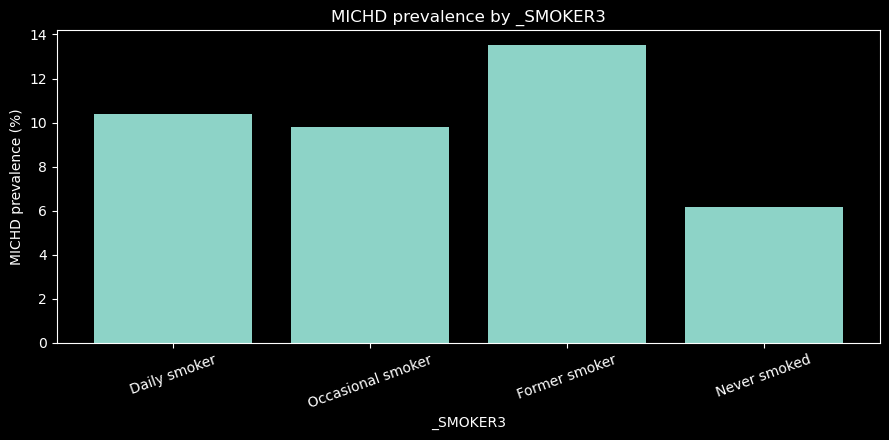

Daily smoker         | N =  32444 | MICHD = 10.37%
Occasional smoker    | N =  13230 | MICHD = 9.80%
Former smoker        | N =  90838 | MICHD = 13.51%
Never smoked         | N = 178357 | MICHD = 6.17%


(array([10.37171742,  9.80347695, 13.51196636,  6.16740582]),
 array([ 32444,  13230,  90838, 178357]))

In [17]:
plot_categorical_prevalence(
    "_SMOKER3",
    [1, 2, 3, 4],
    ["Daily smoker", "Occasional smoker",
     "Former smoker", "Never smoked"]
)

### Findings — Smoking Status

MICHD prevalence differs substantially across smoking categories. Former smokers exhibit the highest prevalence (13.51%), followed by daily smokers (10.37%) and occasional smokers (9.80%). Respondents who never smoked regularly have the lowest prevalence (6.17%).

The higher prevalence among former smokers may reflect differences in age, cumulative smoking exposure, or smoking cessation following a cardiovascular diagnosis.

Age-stratified analysis is needed to investigate potential confounding. These results support retaining smoking status as a candidate predictor, but do not establish causal relationships.

### Smoking status within age groups

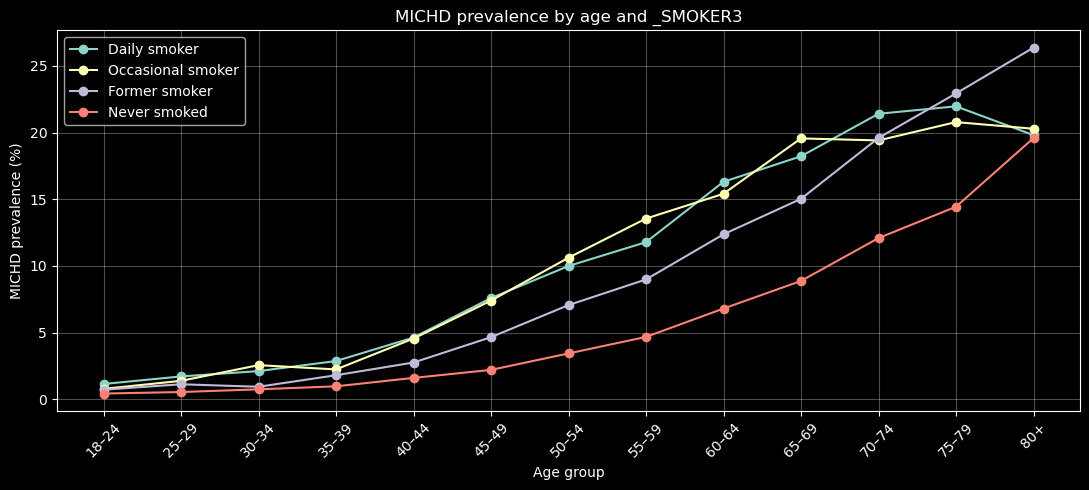

{'Daily smoker': array([1585, 1820, 2330, 2343, 2315, 2808, 4215, 4405, 3943, 3138, 1910,
         933,  535]),
 'Occasional smoker': array([1039, 1020, 1059, 1032,  924, 1001, 1451, 1535, 1473, 1242,  716,
         380,  276]),
 'Former smoker': array([ 1274,  1973,  3125,  3736,  3641,  4473,  6731,  9397, 11545,
        13433, 11840,  8666, 10198]),
 'Never smoked': array([13405,  9201,  9786, 10399, 11615, 13399, 16159, 17824, 19005,
        17631, 12685, 10105, 14836])}

In [18]:
plot_age_stratified(
    "_SMOKER3",
    [1, 2, 3, 4],
    ["Daily smoker", "Occasional smoker",
     "Former smoker", "Never smoked"]
)

### Findings — Smoking Status

MICHD prevalence increases strongly with age across all smoking categories. Respondents who never smoked consistently exhibit the lowest prevalence.

The higher aggregate prevalence among former smokers (13.51%) appears to be partly explained by their older age distribution. After stratifying by age, current smokers often exhibit higher MICHD prevalence than former smokers, particularly in middle-aged groups.

**A particularly interesting and somewhat counterintuitive finding is the limited difference between daily and occasional smokers.** Their aggregate MICHD prevalences are remarkably similar (10.37% vs. 9.80%), and their age-stratified curves largely overlap. This suggests that reported smoking frequency alone may not strongly distinguish cardiovascular disease prevalence among current smokers.

However, `_SMOKER3` does not capture smoking intensity, duration, or cumulative exposure. Furthermore, the observed similarity does not establish that daily and occasional smoking carry equivalent cardiovascular risks.

Overall, smoking status appears to provide relevant predictive information beyond age, supporting its inclusion as a candidate feature.

## 7. Alcohol consumption: investigating a counterintuitive association

Current drinkers initially appear to have **lower MICHD prevalence** than non-drinkers. We do **not** interpret this as evidence that drinking protects against heart disease. People may reduce or stop drinking after a diagnosis, because of medical advice, or because of medication-related contraindications. The two groups can also differ in age and underlying health.

The aim here is to see how far these population differences can account for the observed association, and to illustrate why a useful predictive feature is not necessarily causal.

### 7.1 Any alcohol consumption in the past 30 days (`DRNKANY5`)

`1` = yes, `2` = no. Other response codes are excluded from prevalence calculations.

In [19]:
alcohol = get_feature("DRNKANY5")

values, counts = np.unique(alcohol, return_counts=True)

for value, count in zip(values, counts):
    print(f"{value}: {count} ({100 * count / len(alcohol):.2f}%)")

1.0: 157605 (48.03%)
2.0: 154556 (47.10%)
7.0: 2306 (0.70%)
9.0: 13668 (4.17%)


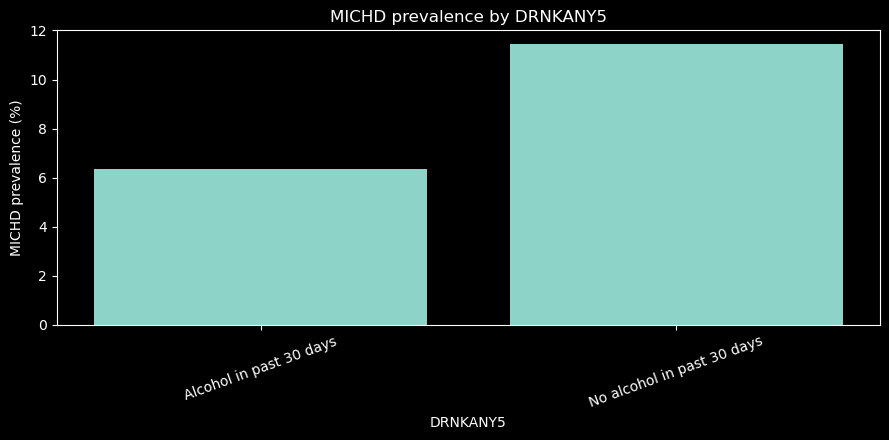

Alcohol in past 30 days | N = 157605 | MICHD = 6.37%
No alcohol in past 30 days | N = 154556 | MICHD = 11.43%


(array([ 6.36845278, 11.43404332]), array([157605, 154556]))

In [20]:
plot_categorical_prevalence(
    "DRNKANY5",
    [1, 2],
    ["Alcohol in past 30 days", "No alcohol in past 30 days"]
)

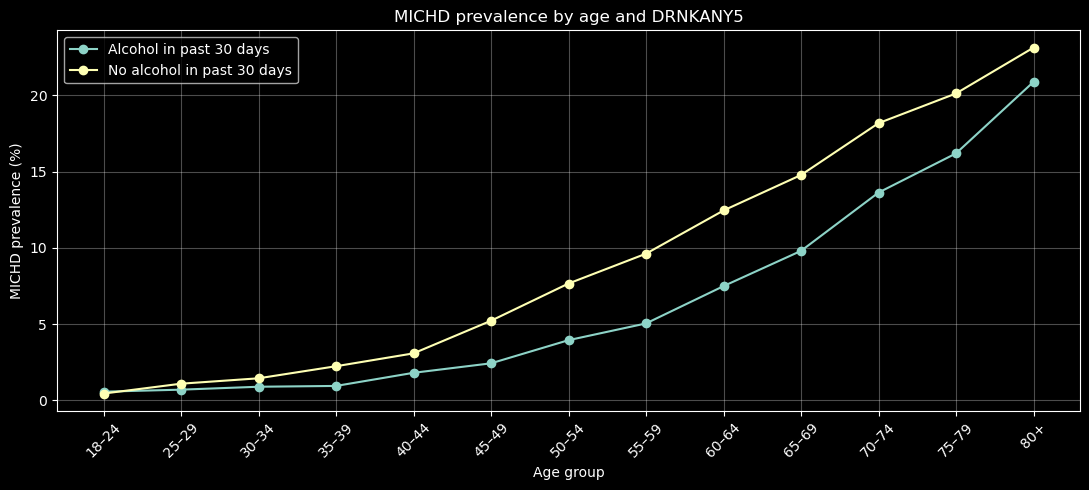

{'Alcohol in past 30 days': array([ 9017,  8724,  9545, 10068, 10585, 12277, 15483, 17268, 17940,
        16860, 11784,  7913,  8788]),
 'No alcohol in past 30 days': array([ 8126,  5137,  6647,  7288,  7758,  9213, 12789, 15622, 17753,
        18320, 15201, 12040, 16802])}

In [21]:
plot_age_stratified(
    "DRNKANY5",
    [1, 2],
    ["Alcohol in past 30 days", "No alcohol in past 30 days"]
)

### Findings — Alcohol Consumption

Respondents reporting alcohol consumption in the past 30 days exhibit substantially lower MICHD prevalence than non-drinkers (6.37% vs. 11.43%).

Interestingly, this counterintuitive association persists across nearly all age groups, suggesting that differences in age distribution alone do not fully explain the observed pattern.

However, the result should not be interpreted as evidence of a protective effect of alcohol. Potential explanations include reverse causality, the *sick quitter effect*, residual confounding, and survivorship bias.

Moreover, `DRNKANY5` does not distinguish occasional from heavy drinkers, nor lifelong abstainers from former drinkers. Investigating alcohol consumption intensity may provide additional insights.

### 7.2 Estimated drinks per week (`_DRNKWEK`)

The BRFSS-derived value is recorded in hundredths of a drink; `99900` denotes missing/unknown. We clean this before making plots.

Valid values: 309168
Median drinks/week: 0.23


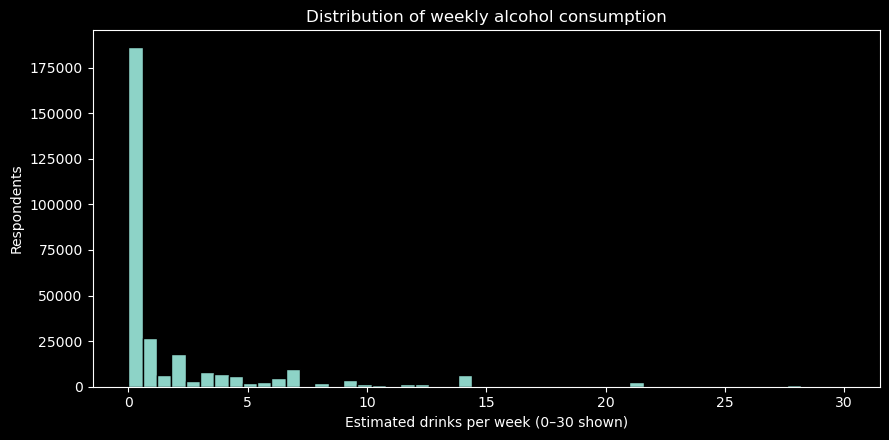

In [22]:
drinks = get_feature("_DRNKWEK").astype(float).copy()
drinks[drinks == 99900] = np.nan  # BRFSS missing/unknown code
drinks /= 100  # drinks per week

print("Valid values:", np.sum(~np.isnan(drinks)))
print("Median drinks/week:", np.nanmedian(drinks))

plt.figure(figsize=(9, 4.5))
plt.hist(drinks[~np.isnan(drinks)], bins=50, range=(0, 30), edgecolor="black")
plt.xlabel("Estimated drinks per week (0–30 shown)")
plt.ylabel("Respondents")
plt.title("Distribution of weekly alcohol consumption")
plt.tight_layout()
plt.show()

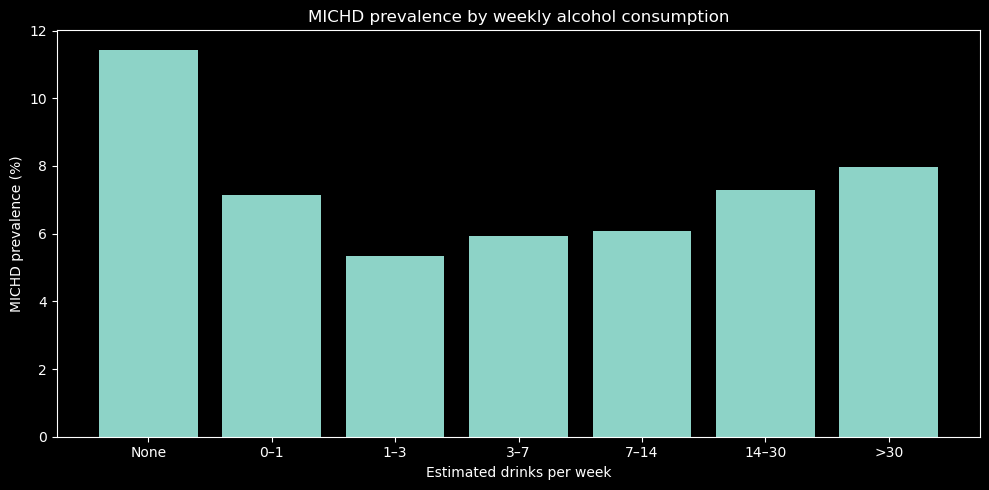

None     | N = 154556 | MICHD = 11.43%
0–1      | N =  54301 | MICHD = 7.14%
1–3      | N =  35093 | MICHD = 5.34%
3–7      | N =  36738 | MICHD = 5.93%
7–14     | N =  18718 | MICHD = 6.07%
14–30    | N =   7136 | MICHD = 7.30%
>30      | N =   2626 | MICHD = 7.96%


In [23]:
drink_edges = [0, 1, 3, 7, 14, 30, np.inf]
drink_labels = ["None", "0–1", "1–3", "3–7", "7–14", "14–30", ">30"]
drink_masks = [drinks == 0] + [
    (drinks > low) & (drinks <= high)
    for low, high in zip(drink_edges[:-1], drink_edges[1:])
]

counts = [mask.sum() for mask in drink_masks]
prevalences = [
    100 * np.mean(y_train[mask] == 1) if mask.any() else np.nan
    for mask in drink_masks
]

plt.figure(figsize=(10, 5))
plt.bar(drink_labels, prevalences)
plt.xlabel("Estimated drinks per week")
plt.ylabel("MICHD prevalence (%)")
plt.title("MICHD prevalence by weekly alcohol consumption")
plt.tight_layout()
plt.show()

for label, n, p in zip(drink_labels, counts, prevalences):
    print(f"{label:8s} | N = {n:6d} | MICHD = {p:.2f}%")

### Findings — Weekly Alcohol Consumption

MICHD prevalence exhibits an approximately J-shaped association with estimated weekly alcohol consumption. Non-drinkers show the highest prevalence (11.43%), while the lowest prevalence is observed among respondents consuming 1–3 drinks per week (5.34%).

Among drinkers, prevalence generally increases with consumption, reaching 7.96% for those reporting more than 30 drinks per week.

**This counterintuitive pattern does not establish a protective effect of moderate alcohol consumption.** Potential explanations include reverse causality, the sick quitter effect, differences in age and sex distributions, and other unmeasured confounding factors.

The results suggest that alcohol consumption intensity may provide additional predictive information beyond the binary drinking indicator, motivating further age- and sex-stratified analysis.

#### Weekly consumption within age groups

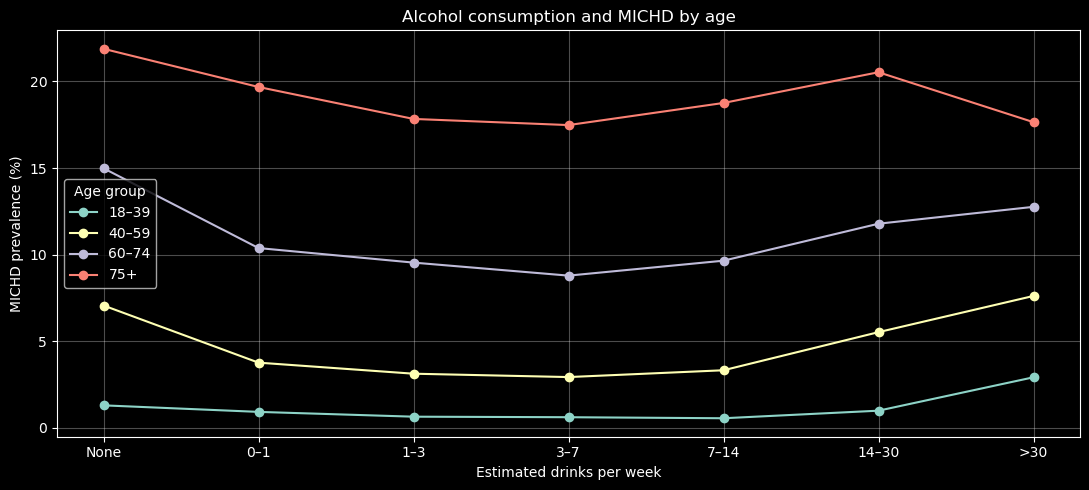

In [24]:
age = get_feature("_AGEG5YR")
age_groups = {"18–39": (1, 4), "40–59": (5, 8), "60–74": (9, 11), "75+": (12, 13)}

plt.figure(figsize=(11, 5))
for label, (low, high) in age_groups.items():
    age_mask = (age >= low) & (age <= high)
    prevalences = []
    for drink_mask in drink_masks:
        mask = age_mask & drink_mask
        prevalences.append(
            100 * np.mean(y_train[mask] == 1) if mask.sum() >= 100 else np.nan
        )
    plt.plot(drink_labels, prevalences, marker="o", label=label)

plt.xlabel("Estimated drinks per week")
plt.ylabel("MICHD prevalence (%)")
plt.title("Alcohol consumption and MICHD by age")
plt.legend(title="Age group")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Could general health explain some of the difference?

We first compare diabetes and perceived general health across current drinkers and non-drinkers. Health status may be both a confounder and a consequence of cardiovascular disease; all comparisons remain descriptive.

**Potential confounding by health status.** The higher MICHD prevalence among non-drinkers may partly reflect pre-existing health conditions. Individuals with chronic diseases or previous cardiovascular events may avoid or discontinue alcohol consumption for medical reasons.

Since the dataset only records recent alcohol consumption, lifelong abstainers cannot be distinguished from individuals who stopped drinking due to illness. This creates potential health-related confounding and reverse causality, which may contribute to the observed J-shaped association.

Further analysis comparing the clinical profiles of drinkers and non-drinkers could help investigate this hypothesis, although the cross-sectional data cannot establish causal relationships.

In [25]:
alcohol = get_feature("DRNKANY5")
diabetes = get_feature("DIABETE3")

for category, label in [(1, "Drinkers"), (2, "Non-drinkers")]:
    mask = (alcohol == category) & np.isin(diabetes, [1, 3])

    diabetes_rate = np.mean(diabetes[mask] == 1) * 100

    print(f"{label}: {diabetes_rate:.2f}% with diabetes")

Drinkers: 8.14% with diabetes
Non-drinkers: 18.61% with diabetes


In [26]:
alcohol = get_feature("DRNKANY5")
diabetes = get_feature("DIABETE3")

for diabetes_code, diabetes_label in [
    (1, "Diabetes"),
    (3, "No diabetes")
]:
    print(f"\n{diabetes_label}")

    for alcohol_code, alcohol_label in [
        (1, "Drinkers"),
        (2, "Non-drinkers")
    ]:
        mask = (
                (diabetes == diabetes_code) &
                (alcohol == alcohol_code)
        )

        n = np.sum(mask)
        prevalence = 100 * np.mean(y_train[mask] == 1)

        print(
            f"{alcohol_label:15s} | "
            f"N = {n:6d} | "
            f"MICHD = {prevalence:.2f}%"
        )


Diabetes
Drinkers        | N =  12542 | MICHD = 18.56%
Non-drinkers    | N =  27847 | MICHD = 23.77%

No diabetes
Drinkers        | N = 141484 | MICHD = 5.22%
Non-drinkers    | N = 121810 | MICHD = 8.56%


### Findings — Alcohol Consumption and Health Status

Non-drinkers exhibit substantially higher diabetes prevalence than current drinkers (18.61% vs. 8.14%), suggesting differences in underlying health status.

After stratifying by diabetes status, non-drinkers still exhibit higher MICHD prevalence in both groups:

- **With diabetes:** 23.77% vs. 18.56%.
- **Without diabetes:** 8.56% vs. 5.22%.

These findings are consistent with health-related confounding contributing to the observed association between alcohol consumption and MICHD, although diabetes alone does not fully account for the difference.

The results do not imply that alcohol consumption protects against cardiovascular disease. Reverse causality, pre-existing illnesses, and other confounding factors remain plausible explanations.

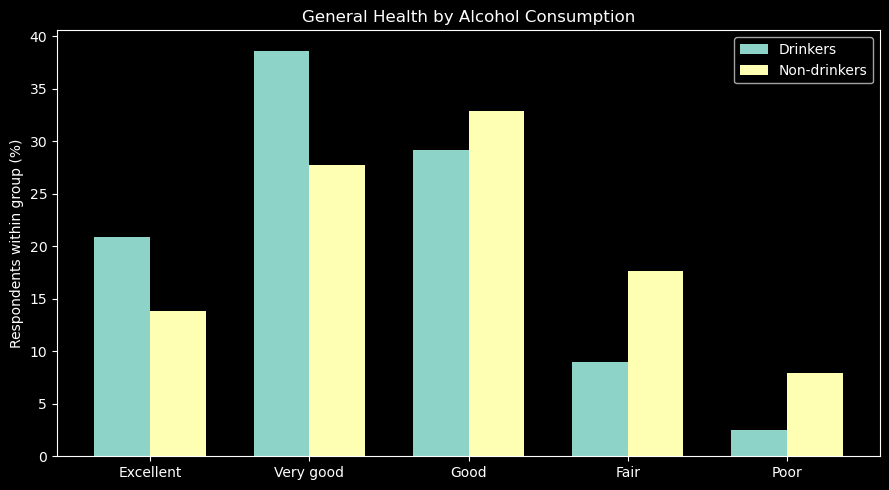

In [27]:
health = get_feature("GENHLTH")
alcohol = get_feature("DRNKANY5")

health_codes = [1, 2, 3, 4, 5]
health_labels = ["Excellent", "Very good", "Good", "Fair", "Poor"]

distributions = []

for alcohol_code in [1, 2]:
    mask = (alcohol == alcohol_code) & np.isin(health, health_codes)
    counts = np.array([
        np.sum(mask & (health == k))
        for k in health_codes
    ])
    distributions.append(100 * counts / counts.sum())

x = np.arange(len(health_codes))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width / 2, distributions[0], width, label="Drinkers")
plt.bar(x + width / 2, distributions[1], width, label="Non-drinkers")

plt.xticks(x, health_labels)
plt.ylabel("Respondents within group (%)")
plt.title("General Health by Alcohol Consumption")
plt.legend()
plt.tight_layout()
plt.show()

Drinkers     | Excellent  | N =  32776 | MICHD = 1.71%
Drinkers     | Very good  | N =  60766 | MICHD = 3.64%
Drinkers     | Good       | N =  45855 | MICHD = 8.09%
Drinkers     | Fair       | N =  14050 | MICHD = 17.41%
Drinkers     | Poor       | N =   3911 | MICHD = 27.64%
Non-drinkers | Excellent  | N =  21253 | MICHD = 2.57%
Non-drinkers | Very good  | N =  42719 | MICHD = 5.12%
Non-drinkers | Good       | N =  50553 | MICHD = 10.24%
Non-drinkers | Fair       | N =  27218 | MICHD = 20.49%
Non-drinkers | Poor       | N =  12255 | MICHD = 33.33%


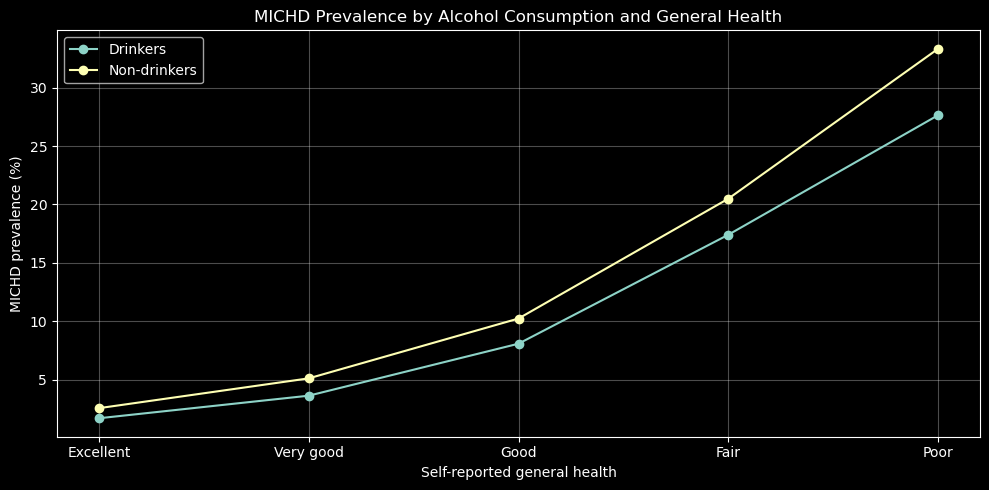

In [28]:
plt.figure(figsize=(10, 5))

for alcohol_code, label in [(1, "Drinkers"), (2, "Non-drinkers")]:
    prevalences = []

    for k in health_codes:
        mask = (alcohol == alcohol_code) & (health == k)

        n = np.sum(mask)
        prevalence = 100 * np.mean(y_train[mask] == 1) if n > 0 else np.nan

        prevalences.append(prevalence)

        print(f"{label:12s} | {health_labels[k - 1]:10s} | "
              f"N = {n:6d} | MICHD = {prevalence:.2f}%")

    plt.plot(health_labels, prevalences, marker="o", label=label)

plt.xlabel("Self-reported general health")
plt.ylabel("MICHD prevalence (%)")
plt.title("MICHD Prevalence by Alcohol Consumption and General Health")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Direct standardization by general health

For each alcohol group, we calculate MICHD prevalence within each general-health category and average using a shared reference distribution. This adjusts the *descriptive comparison* for different category mixes; it is not a causal estimate.

In [29]:
alcohol = get_feature("DRNKANY5")
health = get_feature("GENHLTH")

valid = np.isin(alcohol, [1, 2]) & np.isin(health, [1, 2, 3, 4, 5])

# Reference health distribution
health_weights = np.array([
    np.mean(health[valid] == h)
    for h in range(1, 6)
])

for code, label in [(1, "Drinkers"), (2, "Non-drinkers")]:
    raw = np.mean(y_train[valid & (alcohol == code)] == 1)

    conditional = np.array([
        np.mean(y_train[valid & (alcohol == code) & (health == h)] == 1)
        for h in range(1, 6)
    ])

    standardized = np.sum(conditional * health_weights)

    print(f"{label}:")
    print(f"  Raw prevalence:          {100 * raw:.2f}%")
    print(f"  Standardized prevalence: {100 * standardized:.2f}%")

Drinkers:
  Raw prevalence:          6.36%
  Standardized prevalence: 7.75%
Non-drinkers:
  Raw prevalence:          11.41%
  Standardized prevalence: 9.76%


### 7.4 Chronic conditions among people reporting good health

Someone can report *excellent*, *very good* or *good* health while living with a controlled chronic condition. We test whether the groups still differ in their clinical histories.

In [30]:
alcohol = get_feature("DRNKANY5")
health = get_feature("GENHLTH")
good_health = np.isin(health, [1, 2, 3])

conditions = {
    "High BP": ("BPHIGH4", 1, [1, 2, 3, 4]),
    "Diabetes": ("DIABETE3", 1, [1, 2, 3, 4]),
    "Kidney disease": ("CHCKIDNY", 1, [1, 2]),
    "COPD": ("CHCCOPD1", 1, [1, 2]),
    "Stroke": ("CVDSTRK3", 1, [1, 2]),
}

for name, (feature, positive_code, valid_codes) in conditions.items():
    values = get_feature(feature)
    print(f"\n{name}")
    for code, label in [(1, "Drinkers"), (2, "Non-drinkers")]:
        mask = good_health & (alcohol == code) & np.isin(values, valid_codes)
        p = 100 * np.mean(values[mask] == positive_code) if mask.any() else np.nan
        print(f"  {label:13s}: {p:.2f}% (N={mask.sum()})")


High BP
  Drinkers     : 32.33% (N=139146)
  Non-drinkers : 38.86% (N=114200)

Diabetes
  Drinkers     : 6.12% (N=139287)
  Non-drinkers : 12.62% (N=114354)

Kidney disease
  Drinkers     : 1.73% (N=139214)
  Non-drinkers : 2.69% (N=114275)

COPD
  Drinkers     : 3.75% (N=139053)
  Non-drinkers : 5.69% (N=114083)

Stroke
  Drinkers     : 1.81% (N=139240)
  Non-drinkers : 3.40% (N=114325)


### Findings — Alcohol Consumption and Underlying Health Conditions

Non-drinkers exhibit substantially higher MICHD prevalence than current drinkers (11.43% vs. 6.37%). Standardizing for self-reported general health reduces this difference by approximately 60%, suggesting that health-status composition is strongly associated with the observed pattern.

Interestingly, even among respondents reporting excellent, very good, or good health, non-drinkers show higher prevalence of all five chronic conditions examined. Diabetes (12.62% vs. 6.12%) and previous stroke (3.40% vs. 1.81%) are particularly notable.

**This suggests that self-reported general health does not fully capture underlying clinical differences between drinkers and non-drinkers.** Individuals with controlled chronic conditions may report good health while avoiding alcohol because of medical advice or medication-related contraindications.

However, the data do not establish why respondents abstain from alcohol. Age-related confounding, reverse causality, and unobserved medical factors remain possible explanations.

Overall, these findings highlight why the apparent inverse association between alcohol consumption and MICHD should not be interpreted as evidence of a protective effect.

#### Chronic conditions within age groups

We additionally stratify the good-health sample by age. As before, bins with fewer than 100 observations are left blank.

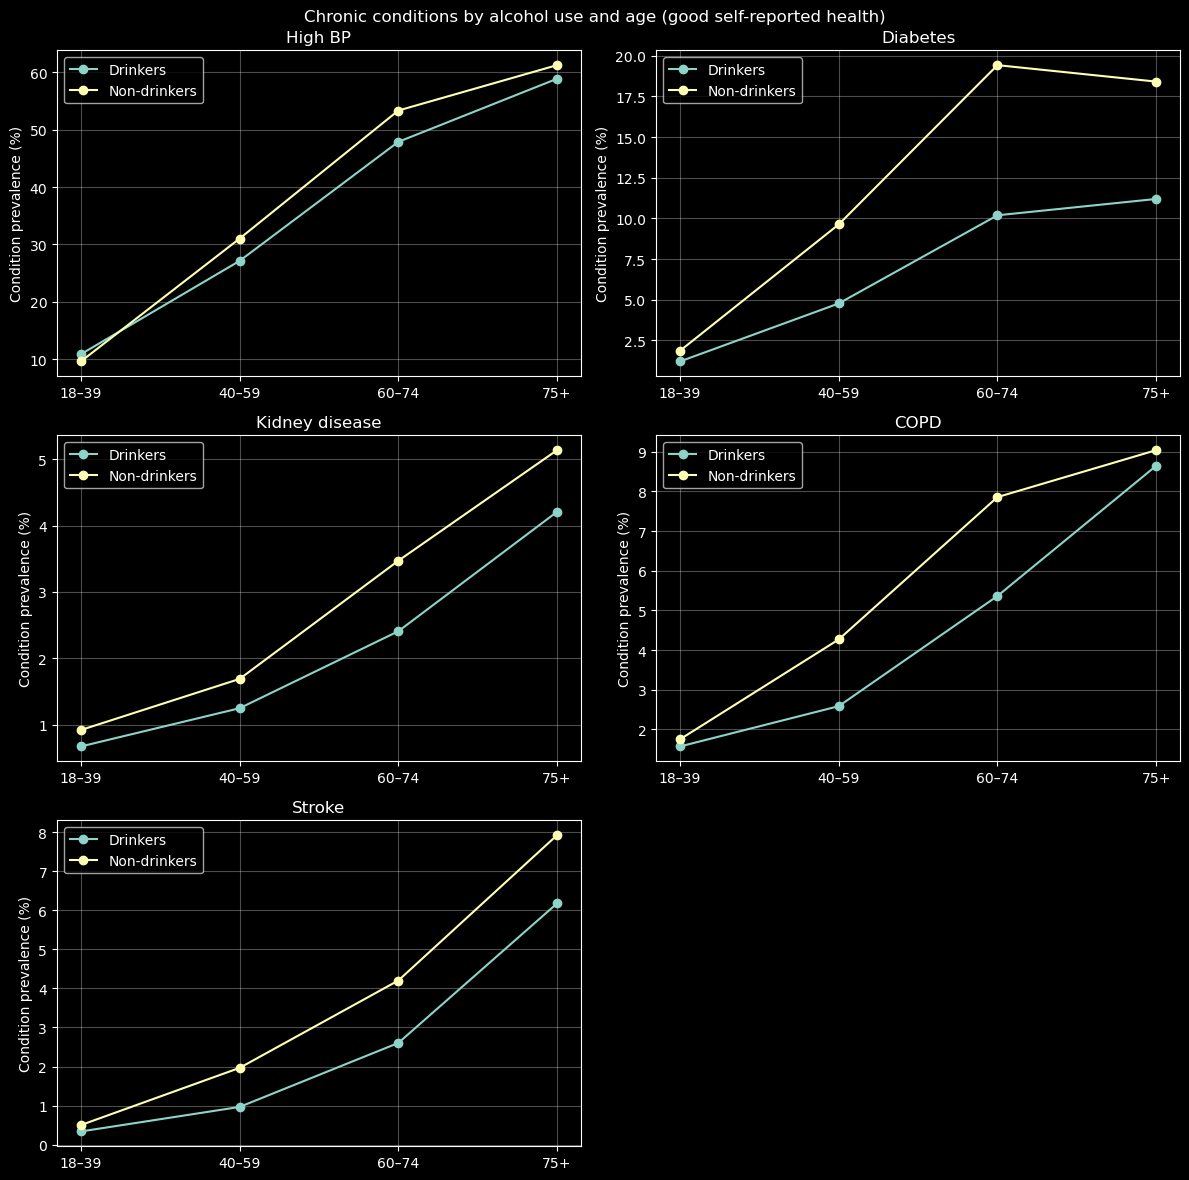

In [31]:
age = get_feature("_AGEG5YR")
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, (name, (feature, positive_code, valid_codes)) in zip(axes.flat, conditions.items()):
    values = get_feature(feature)
    valid = good_health & np.isin(values, valid_codes)

    for alcohol_code, label in [(1, "Drinkers"), (2, "Non-drinkers")]:
        prevalences = []
        for low, high in age_groups.values():
            mask = valid & (alcohol == alcohol_code) & (age >= low) & (age <= high)
            prevalences.append(
                100 * np.mean(values[mask] == positive_code)
                if mask.sum() >= 100 else np.nan
            )
        ax.plot(list(age_groups), prevalences, marker="o", label=label)

    ax.set(title=name, ylabel="Condition prevalence (%)")
    ax.grid(alpha=0.3)
    ax.legend()

axes.flat[-1].set_visible(False)
fig.suptitle("Chronic conditions by alcohol use and age (good self-reported health)")
fig.tight_layout()
plt.show()

### Findings — Alcohol Abstinence and Underlying Health Conditions

Among respondents reporting excellent, very good, or good general health, non-drinkers exhibit higher prevalence of hypertension, diabetes, kidney disease, COPD, and previous stroke.

These differences persist across age groups, with particularly pronounced disparities in diabetes and stroke prevalence.

**This suggests that self-reported general health does not fully capture clinical differences between drinkers and non-drinkers.** Individuals with controlled chronic conditions may report good health while avoiding alcohol because of medical advice or medication-related contraindications.

Together with the substantial reduction in the MICHD prevalence gap after standardization for general health, these findings provide a plausible explanation for part of the counterintuitive association between alcohol consumption and MICHD.

However, the proposed medication-related mechanism cannot be verified using the available data. Residual confounding, reverse causality, and differences in previous drinking history remain possible explanations.

## 8. Redundant features and implications for preprocessing

We check exact duplicates, treating `NaN` in matching positions as equal. This does not detect features that encode the same information in different ways, but it is a useful first check.

In [32]:
duplicate_pairs = []

for i in range(x_train.shape[1]):
    for j in range(i + 1, x_train.shape[1]):
        if np.array_equal(
                x_train[:, i],
                x_train[:, j],
                equal_nan=True
        ):
            duplicate_pairs.append(
                (feature_names[i], feature_names[j])
            )

print("Exact duplicate pairs:", len(duplicate_pairs))

for pair in duplicate_pairs[:30]:
    print(pair)

KeyboardInterrupt: 

### Confirm duplicates in the test features

This is a feature consistency check only. We do not use any test labels or tune models on the test set.

In [ ]:
duplicate_pairs = [
    ("SEQNO", "_PSU"),
    ("CTELNUM1", "CELLFON2"),
    ("_CRACE1", "_CPRACE")
]

for a, b in duplicate_pairs:
    i = np.where(feature_names == a)[0][0]
    j = np.where(feature_names == b)[0][0]

    same_train = np.array_equal(
        x_train[:, i], x_train[:, j], equal_nan=True
    )
    same_test = np.array_equal(
        x_test[:, i], x_test[:, j], equal_nan=True
    )

    print(f"{a:10s} / {b:10s} | Train: {same_train} | Test: {same_test}")

In [ ]:
i = np.flatnonzero(feature_names == "CTELNUM1")[0]
j = np.flatnonzero(feature_names == "CELLFON2")[0]
a, b = x_test[:, i], x_test[:, j]

same = (a == b) | (np.isnan(a) & np.isnan(b))
print(f"CTELNUM1 vs CELLFON2 — different test rows: {(~same).sum()}")
print(f"Share: {100*np.mean(~same):.6f}%")

Make figure for report

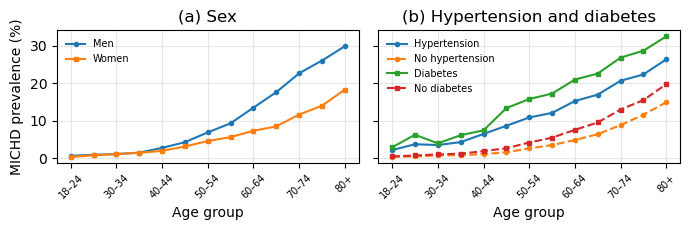

In [34]:
plt.style.use("default")
def michd_rate_by_age(feature, category):
    """MICHD prevalence (%) per 5-year age group, among rows with feature == category."""
    ages, values = get_feature("_AGEG5YR"), get_feature(feature)
    return np.array([100 * np.mean(y_train[(ages == a) & (values == category)] == 1)
                     for a in range(1, 14)])          # 14 = age missing

x = np.arange(13)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2.4), sharey=True)

ax1.plot(x, michd_rate_by_age("SEX", 1), "o-", ms=3, label="Men")
ax1.plot(x, michd_rate_by_age("SEX", 2), "s-", ms=3, label="Women")
ax1.set(ylabel="MICHD prevalence (%)", title="(a) Sex")

ax2.plot(x, michd_rate_by_age("BPHIGH4", 1), "o-", ms=3, label="Hypertension")
ax2.plot(x, michd_rate_by_age("BPHIGH4", 3), "o--", ms=3, label="No hypertension")
ax2.plot(x, michd_rate_by_age("DIABETE3", 1), "s-", ms=3, label="Diabetes")
ax2.plot(x, michd_rate_by_age("DIABETE3", 3), "s--", ms=3, label="No diabetes")
ax2.set(title="(b) Hypertension and diabetes")

for ax in (ax1, ax2):
    ax.set_xticks(x[::2], [AGE_LABELS[i] for i in x[::2]], rotation=45, fontsize=7)
    ax.set_xlabel("Age group")
    ax.legend(fontsize=7, frameon=False)
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("michd_by_age.pdf", bbox_inches="tight")
plt.show()

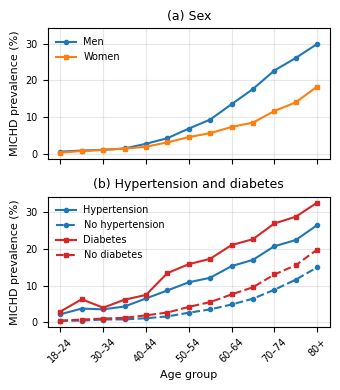

In [36]:
import matplotlib as mpl

def michd_rate_by_age(feature, category):
    """MICHD prevalence (%) per 5-year age group, among rows with feature == category."""
    ages, values = get_feature("_AGEG5YR"), get_feature(feature)
    return np.array([100 * np.mean(y_train[(ages == a) & (values == category)] == 1)
                     for a in range(1, 14)])          # 14 = age missing

x = np.arange(13)

with mpl.rc_context(mpl.rcParamsDefault), plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.5, 4), sharex=True, sharey=True,
                                   facecolor="white")

    ax1.plot(x, michd_rate_by_age("SEX", 1), "o-", ms=3, label="Men")
    ax1.plot(x, michd_rate_by_age("SEX", 2), "s-", ms=3, label="Women")
    ax1.set_title("(a) Sex", fontsize=9)

    ax2.plot(x, michd_rate_by_age("BPHIGH4", 1), "o-", ms=3, color="C0", label="Hypertension")
    ax2.plot(x, michd_rate_by_age("BPHIGH4", 3), "o--", ms=3, color="C0", label="No hypertension")
    ax2.plot(x, michd_rate_by_age("DIABETE3", 1), "s-", ms=3, color="C3", label="Diabetes")
    ax2.plot(x, michd_rate_by_age("DIABETE3", 3), "s--", ms=3, color="C3", label="No diabetes")
    ax2.set_title("(b) Hypertension and diabetes", fontsize=9)
    ax2.set_xticks(x[::2], [AGE_LABELS[i] for i in x[::2]], rotation=45, fontsize=7)
    ax2.set_xlabel("Age group", fontsize=8)

    for ax in (ax1, ax2):
        ax.set_facecolor("white")
        ax.set_ylabel("MICHD prevalence (%)", fontsize=8)
        ax.tick_params(axis="y", labelsize=7)
        ax.legend(fontsize=7, frameon=False, loc="upper left")
        ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig("michd_by_age.pdf", bbox_inches="tight", facecolor="white", transparent=False)
    plt.show()